1. ¿Qué es el análisis exploratorio de datos?

El análisis exploratorio de datos, conocido como EDA (Exploratory Data Analysis), es el proceso de examinar, estudiar y comprender un conjunto de datos para encontrar patrones,
tendencias,relaciones y comportamientos.

En palabras sencillas:
- En la limpieza preguntábamos: ¿están correctos nuestros datos?
- En el análisis exploratorio preguntamos: ¿qué información podemos descubrir con estos datos?

Por ejemplo, tenemos 3,801 registros de partidos y 34 columnas. Podemos investigar:

- ¿Qué equipos anotaron más puntos?
- ¿Cuál fue el promedio de puntos por partido?
- ¿Qué semanas tuvieron más partidos?
- ¿Qué equipos ganaron más encuentros?
- ¿Cuántos partidos se completaron?
- ¿Existe alguna relación entre la asistencia y los puntos anotados?

¿Qué vamos a hacer durante el EDA?
Vamos a dividirlo en cuatro partes:



1. Análisis de una variable (univariado)

Estudiar una columna individualmente.

Ejemplo: distribución de puntos anotados por los equipos.

2. Análisis de dos variables (bivariado)

Estudiar la relación entre dos columnas.

Ejemplo: asistencia al estadio y puntos anotados.

3. Análisis de varias variables (multivariado)

Estudiar varias columnas para encontrar relaciones.

Ejemplo: equipo, semana, puntos y resultados.

4. Visualización de datos

Representar los resultados mediante gráficos para comprender mejor los patrones.

Y comenzaremos investigando preguntas reales:

1. ¿Cuántos partidos se jugaron?
2. ¿Cuáles fueron los equipos con mayor puntuación?
3. ¿Cuál fue el promedio de puntos por partido?
4. ¿Qué semanas tuvieron más encuentros?
5. ¿Qué equipos ganaron más partidos?

EDA — Paso 1: conocer la distribución de los puntos

Antes de comenzar, recuerda que tenemos nuestro archivo partidos_2024_limpio.csv, con 3,801 registros y 34 columnas.

1. Nuestra primera pregunta
¿Cómo se distribuyen los puntos anotados por los equipos locales?

Queremos conocer:
- Cuántos puntos suelen anotar.
- Cuál es el promedio de puntos.
- Cuál es la puntuación mínima y máxima.
- Si existen equipos que anotan cantidades muy diferentes a las habituales.

#1.Cargar nuestros datos

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/partidos_2024_limpio.csv")

#2.Calcular las estadísticas

Esta función nos devuelve estadísticas descriptivas:

Resultado	¿Qué significa?

count	/Cantidad de registros con puntuaciones disponibles.

mean	/Promedio de puntos.

std	   / Desviación estándar (variabilidad).

min	   / Puntuación mínima.

25%	   / Primer cuartil.

50%    	/Mediana.

75%	    /Tercer cuartil.

max	    /Puntuación máxima.

In [3]:
df["homePoints"].describe()

count    3799.000000
mean       28.659911
std        15.845976
min         0.000000
25%        17.000000
50%        28.000000
75%        38.000000
max        96.000000
Name: homePoints, dtype: float64

Interpretación de los puntos del equipo local.
Estos son los resultados:

Estadística   /   Resultado	   /   Interpretación

count/=>	  3,799	Hay 3,799 partidos con puntuación local disponible.

mean/=>	       28.66	Los equipos locales anotaron aproximadamente 28.66 puntos en promedio.

std/=>         15.85	Existe una variabilidad considerable en las puntuaciones.

min/=>	      0	La puntuación mínima registrada fue 0.

25%/=>	      17	El 25 % de los registros tiene 17 puntos o menos.

50%/=>	      28	La mitad de los registros tiene 28 puntos o menos.

75%/=>	      38	El 75 % tiene 38 puntos o menos.

max/=> 	      96	La puntuación máxima registrada fue 96.

1. ¿Qué podemos descubrir?
Hay tres observaciones interesantes:

A. Promedio: los equipos locales anotaron unos 28.66 puntos por partido.

B. Mediana: la mitad de las puntuaciones está en 28 puntos o menos. Es decir, la mediana es 28.

C. Diferencia entre mínimo y máximo: tenemos puntuaciones desde 0 hasta 96. Esto nos indica que hay bastante amplitud en los resultados.

Recuerda que count = 3799 porque los dos registros sin puntuación local no participan en este cálculo.

#Vamos a comparar los resultados de los equipos visitantes.

In [4]:
df["awayPoints"].describe()

count    3799.000000
mean       23.945512
std        14.731025
min         0.000000
25%        14.000000
50%        22.000000
75%        34.000000
max        84.000000
Name: awayPoints, dtype: float64

Queremos comprobar si los visitantes anotan mas o menos puntos que los locales.

Despues construiremos nuestro primer histograma para visualizar como se distribuyen las puntuaciones.

1. Interpretación de los equipos visitantes
 
Estadística/	 Resultado/	  Significado

count=>	3,799	Partidos con puntuación disponible

mean=>	23.95	Promedio de puntos visitantes

std=>	14.73	Variación de las puntuaciones

min=>	0	Puntuación mínima

25%=> 14	El 25% anotó 14 puntos o menos

50%=>	22	La mediana fue 22 puntos

75%=>	34	El 75% anotó 34 puntos o menos

max=>	84	Puntuación máxima

2. Comparación: local vs. visitante

Estadística	Local (homePoints)	/  Visitante (awayPoints)

Promedio=>	     /->     28.66	     /->          23.95

Mediana=>        /->  	28	         /->       22

Desviación estándar=>/->	15.85	    /->     14.73

Máximo=>         /->        96	      /->          84

Que podemos observar?

- Los equipos locales anotaron, en promedio, aproximadamente 4.71 puntos más.

- La mediana también es mayor para los equipos locales: 28 frente a 22.

- Las puntuaciones locales presentan un poco más de dispersión.

Esto nos permite formular una primera observación: en este conjunto de partidos, los equipos locales tuvieron un promedio de anotación superior al de los visitantes. Todavía no significa que jugar en casa sea la causa.

#Siguiente paso: visualizar la distribución

Ahora vamos a utilizar un histograma. Nos permitira observar donde se concentran las puntuaciones y que tan frecuentes son los valores altos y bajos.

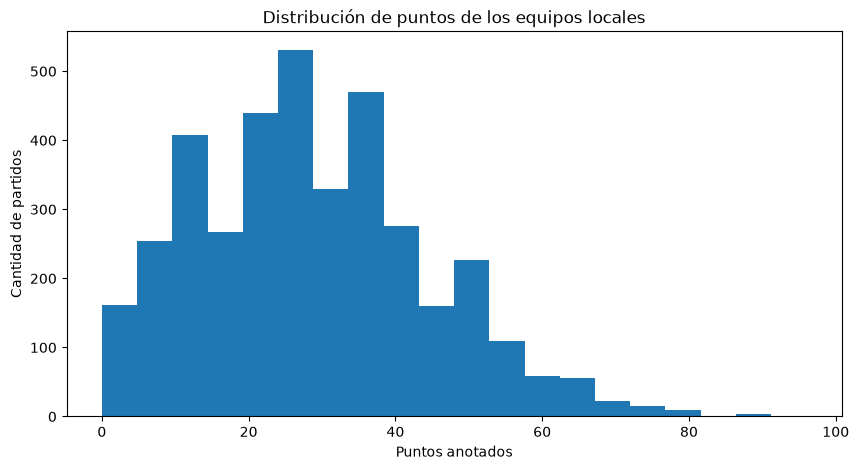

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df["homePoints"].dropna(), bins=20)

plt.title("Distribución de puntos de los equipos locales")
plt.xlabel("Puntos anotados")
plt.ylabel("Cantidad de partidos")

plt.show()

1. ¿Qué representa el gráfico?

Hay dos ejes:
- Eje X (horizontal): representa los puntos anotados por los equipos locales.

- Eje Y (vertical): representa la cantidad de partidos en los que se registró esa puntuación.

Por ejemplo, si una barra llega hasta 500, significa que aproximadamente 500 partidos tuvieron puntuaciones dentro del intervalo que representa esa barra.

2. ¿Qué podemos observar?

Analizando el gráfico:
1. La mayoría de los partidos tienen puntuaciones entre 10 y 40 puntos.
2. Hay una concentración importante entre 20 y 30 puntos.
3. A medida que aumentan los puntos, disminuye la frecuencia.
4. Hay algunos partidos con puntuaciones superiores a 60 y 80 puntos, que son valores poco frecuentes.
Esto nos permite observar que la distribución tiene una cola hacia la derecha.

#La línea más importante para entender es:

plt.hist(df["homePoints"].dropna(), bins=20)



- plt.hist(): construye el histograma.
- df["homePoints"]: selecciona la columna de puntos locales.
- .dropna(): elimina los valores vacíos (NaN).
- bins=20: divide los datos en 20 intervalos para agrupar las puntuaciones.

#==================================================
Paso 1. Visualizar los valores atípicos
¿Por qué hacemos esto?

El histograma nos permitió observar dónde se concentran las puntuaciones. El Boxplot nos permitirá identificar visualmente los valores que se encuentran alejados del comportamiento habitual.

Vamos a comparar los puntos de los equipos locales (homePoints) y visitantes (awayPoints).

In [6]:
# Trabajar solamente con partidos completados
df_eda = df[df["completed"] == True].copy()

# Crear nuestra variable objetivo
df_eda["homeWin"] = (
    df_eda["homePoints"] > df_eda["awayPoints"]
).astype(int)

# Distribución de resultados
print(df_eda["homeWin"].value_counts())

print("\nPorcentajes:")
print(df_eda["homeWin"].value_counts(normalize=True) * 100)

homeWin
1    2182
0    1617
Name: count, dtype: int64

Porcentajes:
homeWin
1    57.436167
0    42.563833
Name: proportion, dtype: float64


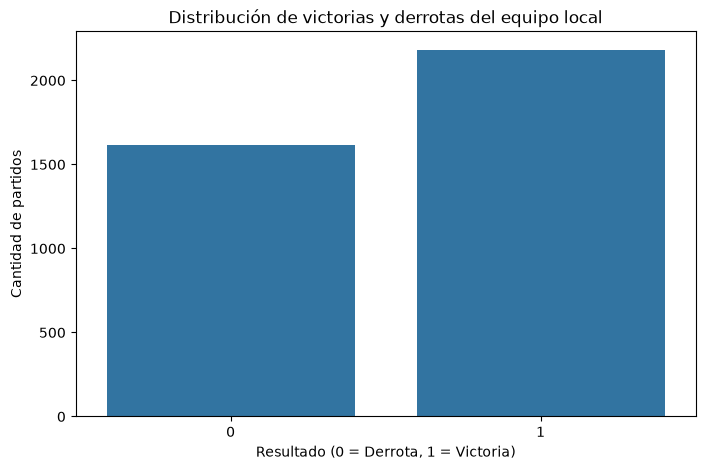

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_eda,
    x="homeWin"
)

plt.title("Distribución de victorias y derrotas del equipo local")
plt.xlabel("Resultado (0 = Derrota, 1 = Victoria)")
plt.ylabel("Cantidad de partidos")

plt.show()

"El gráfico muestra que durante la temporada 2024 los equipos locales ganaron más partidos que los equipos visitantes. Se registraron 2,182 victorias locales frente a 1,617 derrotas locales. Esto representa una proporción de victorias locales del 57.44%, lo que sugiere una posible ventaja de jugar en casa".

In [8]:
# Estadísticas descriptivas de las variables numéricas

estadisticas = df_eda.describe().T

display(estadisticas)

,count,mean,std,min,25%,50%,75%,max
id,3799.0,4.016616e+08,22426.577027,4.016283e+08,4.016387e+08,4.016743e+08,4.016758e+08,4.017412e+08
season,3799.0,2.024000e+03,0.000000,2.024000e+03,2.024000e+03,2.024000e+03,2.024000e+03,2.024000e+03
week,3799.0,7.133193e+00,3.788741,1.000000e+00,4.000000e+00,7.000000e+00,1.000000e+01,1.600000e+01
attendance,1594.0,2.718695e+04,27110.477000,4.530000e+02,6.282250e+03,1.702900e+04,4.145475e+04,1.111700e+05
venueId,3790.0,4.773769e+03,1321.612540,3.600000e+01,3.782000e+03,4.430000e+03,5.907000e+03,1.080300e+04
homeId,3799.0,4.750272e+03,19087.824062,2.000000e+00,2.380000e+02,2.141000e+03,2.583000e+03,1.297380e+05
homePoints,3799.0,2.865991e+01,15.845976,0.000000e+00,1.700000e+01,2.800000e+01,3.800000e+01,9.600000e+01
homePostgameWinProbability,1616.0,6.236117e-01,0.395112,0.000000e+00,1.962824e-01,8.283164e-01,9.865609e-01,1.000000e+00
homePregameElo,919.0,1.522103e+03,236.570194,8.350000e+02,1.371500e+03,1.521000e+03,1.644000e+03,2.169000e+03
homePostgameElo,919.0,1.529575e+03,241.553394,8.050000e+02,1.372500e+03,1.524000e+03,1.665500e+03,2.165000e+03


#Interpretación de homePoints

Esta variable representa los puntos anotados por el equipo local.

- Mean = 28.66: los equipos locales anotaron aproximadamente 28.66 puntos por partido.

- Std = 15.85: existe bastante variación en los puntos anotados.

- Min = 0: hubo partidos donde el equipo local no anotó.

- 25% = 17: el 25% de los partidos tuvo 17 puntos o menos del equipo local.

- 50% = 28: la mitad de los equipos locales anotó 28 puntos o menos.

- 75% = 38: el 75% anotó 38 puntos o menos.

- Max = 96: el máximo registrado fue de 96 puntos.

#Siguiente análisis

Estudiemos la distribución de los puntos anotados por los equipos.

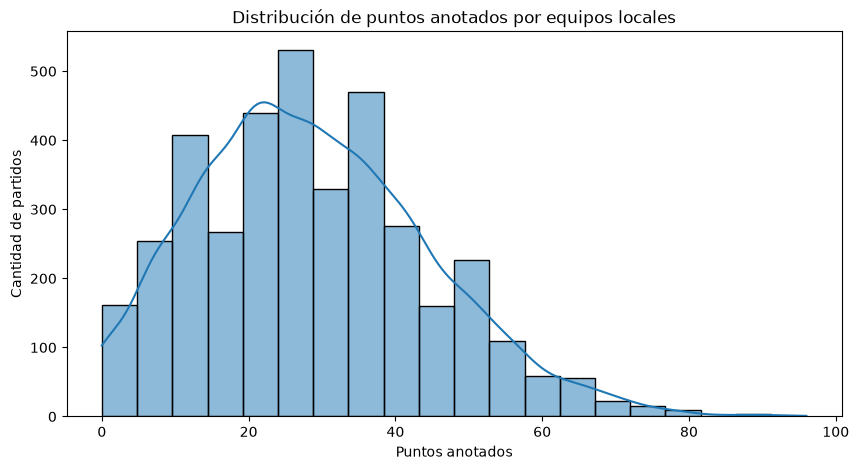

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_eda,
    x="homePoints",
    bins=20,
    kde=True
)

plt.title("Distribución de puntos anotados por equipos locales")
plt.xlabel("Puntos anotados")
plt.ylabel("Cantidad de partidos")

plt.show()

Este gráfico se llama histograma.

Nos permitirá observar:
- Cuáles son los resultados más frecuentes.
- Si los equipos suelen anotar pocos o muchos puntos.
- Si existen resultados extremadamente altos o bajos.
- Cómo se distribuyen los puntos.

Que nos dice el grafico?

Podemos identificar tres cosas:

1. La mayor concentración de partidos está aproximadamente entre 15 y 40 puntos.

2. El intervalo de 20 a 30 puntos presenta una frecuencia especialmente alta.

3. Existe una cola hacia la derecha: hay partidos en los que los equipos 

locales anotaron más de 60 puntos, pero son poco frecuentes.

Esto indica que la distribución tiene una asimetría positiva (hacia la derecha).

Ahora que analizamos la distribución de puntos de los equipos locales, debemos hacer lo mismo con los equipos visitantes 
(AwayPoints).

In [12]:
print(df_eda.columns.tolist())

['id', 'season', 'week', 'seasonType', 'startDate', 'startTimeTBD', 'completed', 'neutralSite', 'conferenceGame', 'attendance', 'venueId', 'venue', 'homeId', 'homeTeam', 'homeClassification', 'homeConference', 'homePoints', 'homeLineScores', 'homePostgameWinProbability', 'homePregameElo', 'homePostgameElo', 'awayId', 'awayTeam', 'awayClassification', 'awayConference', 'awayPoints', 'awayLineScores', 'awayPostgameWinProbability', 'awayPregameElo', 'awayPostgameElo', 'excitementIndex', 'highlights', 'notes', 'playoff', 'homeWin']


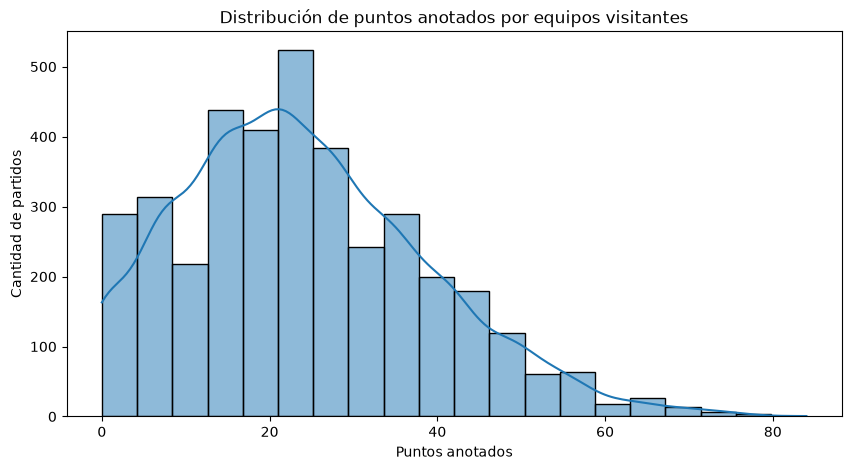

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_eda,
    x="awayPoints",
    bins=20,
    kde=True
)

plt.title("Distribución de puntos anotados por equipos visitantes")
plt.xlabel("Puntos anotados")
plt.ylabel("Cantidad de partidos")

plt.show()

Interpretacion del histograma de visitantes

Observando mi grafico:

- La mayor concentracion de partidos esta aproximadamente entre 10 y 35 puntos.
- El intervalo de 20 a 25 puntos presenta una frecuencia especialmente alta.
- Hay pocos equipos visitantes que superan los 60 puntos.
- También presenta una asimetría positiva (cola hacia la derecha).

#Comparar estadisticamente los puntos de ambos equipos.

In [14]:
df_eda[["homePoints", "awayPoints"]].describe()

,homePoints,awayPoints
count,3799.000000,3799.000000
mean,28.659911,23.945512
std,15.845976,14.731025
min,0.000000,0.000000
25%,17.000000,14.000000
50%,28.000000,22.000000
75%,38.000000,34.000000
max,96.000000,84.000000


Obtener:

- mean: promedio de puntos.
- std: desviación estándar.
- min: puntuación mínima.
- 25%: primer cuartil.
- 50%: mediana.
- 75%: tercer cuartil.
- max: puntuación máxima.

resultados estadísticos para comparar a los equipos locales y visitantes. Y hay algo bastante interesante: los equipos locales anotan más puntos, en promedio, que los visitantes.

A. Promedio (mean)

- Locales: 28.66 puntos.
- Visitantes: 23.95 puntos.

La diferencia es de aproximadamente 4.71 puntos por partido a favor de los equipos locales.

B. Mediana (50%)

- Locales: 28 puntos.
- Visitantes: 22 puntos.

Esto significa que el valor central de los puntos anotados también es mayor para los equipos locales.

C. Desviación estándar (std)
- Locales: 15.85.

Los puntos anotados por los equipos locales presentan una dispersión ligeramente mayor.

3. Primera conclusión del EDA
Con estos resultados podemos formular una primera observación:
En los 3,799 partidos analizados, los equipos locales registraron un promedio de 28.66 puntos, mientras que los visitantes obtuvieron 23.95. Esto representa una diferencia promedio de 4.71 puntos a favor de los equipos locales.

#Calcularemos la diferencia de puntos entre ambos equipos.

In [15]:
# Diferencia de puntos entre equipos locales y visitantes
df_eda["pointDifference"] = (
    df_eda["homePoints"] - df_eda["awayPoints"]
)

# Estadísticas de la diferencia
df_eda["pointDifference"].describe()

count    3799.000000
mean        4.714399
std        25.028752
min       -77.000000
25%       -10.000000
50%         4.000000
75%        21.000000
max        91.000000
Name: pointDifference, dtype: float64

Interpretación de los resultados

Estadística	Resultado	Interpretación

- count:	3,799	Cantidad de partidos analizados

- mean:	+4.71	Ventaja promedio de los locales

- std:	25.03	Dispersión de las diferencias

- min:	-77	Mayor diferencia negativa

- 25%:	-10	El 25% de los partidos tiene diferencias de -10 o menos

- 50%:	+4	Mediana de la diferencia

- 75%:	+21	El 75% de los partidos tiene diferencias de +21 o menos

- max:	+91	Mayor diferencia positiva

Esto nos da a conocer cuanto ganan o pierden los equipos locales respecto a los visitantes.

- Resultado positivo: gano el equipo local.
- Resultado negativo: gano el equipo visitante.
- Resultado cero: empate.

#La frecuencia de victorias locales:

In [16]:
df_eda["homeWin"].value_counts(normalize=True) * 100

homeWin
1    57.436167
0    42.563833
Name: proportion, dtype: float64

Objetivo: determinar si existe una ventaja estadística para los equipos que juegan en casa.

Ahora vamos a visualizar la diferencia de puntos

Ya conocemos los valores estadísticos. Ahora queremos observar cómo se distribuyen las victorias locales y visitantes en términos de margen de puntuación.

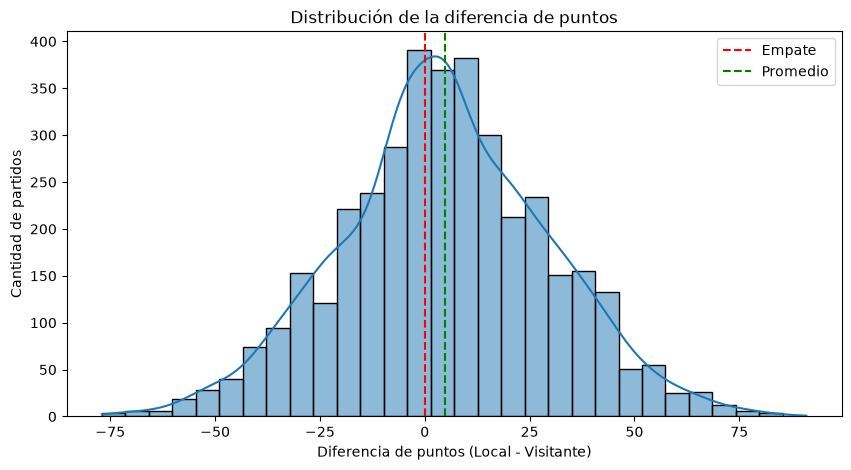

In [17]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_eda,
    x="pointDifference",
    bins=30,
    kde=True
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Empate"
)

plt.axvline(
    df_eda["pointDifference"].mean(),
    color="green",
    linestyle="--",
    label="Promedio"
)

plt.title("Distribución de la diferencia de puntos")
plt.xlabel("Diferencia de puntos (Local - Visitante)")
plt.ylabel("Cantidad de partidos")

plt.legend()
plt.show()

Que aprenderemos con este grafico?

- A la derecha de cero: partidos donde los locales anotaron más.
- A la izquierda de cero: partidos donde los visitantes anotaron más.
- En cero: partidos empatados.
- Línea verde: diferencia promedio (+4.71).
- Línea roja: referencia de empate.

Interpretación del histograma

En tu gráfico podemos identificar:

- Zona izquierda (valores negativos): partidos donde los visitantes anotaron más puntos.
- Zona derecha (valores positivos): partidos donde los locales anotaron más puntos.
- Línea roja (0): representa el empate.
- Línea verde (+4.71): representa la diferencia promedio.

#Que nos dicen los resultados?

Hay tres observaciones:
1. La mayor concentración de partidos está alrededor de diferencias cercanas a cero.
2. La distribución tiene valores positivos y negativos, lo que indica que tanto locales como visitantes consiguen ventajas.
3. El promedio está desplazado hacia la derecha (+4.71), lo que sugiere una ventaja de puntuación para los equipos locales.

#Calcular porcentajes de victorias

In [18]:
# Clasificar los resultados de los partidos

df_eda["resultado"] = "Empate"

df_eda.loc[
    df_eda["pointDifference"] > 0,
    "resultado"
] = "Victoria local"

df_eda.loc[
    df_eda["pointDifference"] < 0,
    "resultado"
] = "Victoria visitante"


# Calcular porcentajes

porcentajes = (
    df_eda["resultado"]
    .value_counts(normalize=True) * 100
)

print(porcentajes)

resultado
Victoria local        57.436167
Victoria visitante    42.221637
Empate                 0.342195
Name: proportion, dtype: float64


Qué significa?

- 57.44%: los equipos locales ganaron aproximadamente 57 de cada 100 partidos.
- 42.22%: los equipos visitantes ganaron aproximadamente 42 de cada 100 partidos.
- 0.34%: una proporción muy pequeña terminó empatada.
La diferencia entre victorias locales y visitantes es de aproximadamente 15.21 puntos porcentuales.

Los resultados muestran que los equipos locales ganaron el 57.44% de los partidos, mientras que los visitantes ganaron el 42.22%. Los empates representaron solamente el 0.34%. Estos resultados sugieren que existe una ventaja asociada a jugar como equipo local.

#Verificar la consistencia de los datos

In [19]:
pd.crosstab(
    df_eda["resultado"],
    df_eda["homeWin"],
    margins=True
)

homeWin,0,1,All
resultado,,,
Empate,13,0,13
Victoria local,0,2182,2182
Victoria visitante,1604,0,1604
All,1617,2182,3799


Esto?

Porque estamos comparando dos cosas:

- resultado: nuestra clasificación creada mediante la diferencia de puntos.
- homeWin: la variable original del dataset.
Esto es una comprobación de calidad de datos (Data Validation).

Así evitamos construir conclusiones sobre variables mal clasificadas.

Los 2,182 partidos clasificados como victorias locales coinciden con homeWin = 1.



Los 1,604 partidos clasificados como victorias visitantes coinciden con homeWin = 0.



Los 13 empates también tienen homeWin = 0, porque el equipo local no ganó.

#Evolución por temporadas

In [20]:
# Calcular porcentaje de victorias locales por temporada

home_advantage = (
    df_eda.groupby("season")["homeWin"]
    .mean() * 100
)

print(home_advantage)

season
2024    57.436167
Name: homeWin, dtype: float64


In [21]:
print(df_eda["season"].value_counts().sort_index())

season
2024    3799
Name: count, dtype: int64


In [22]:
print(df_eda["season"].unique())

[2024]


In [23]:
# Cantidad de valores faltantes por columna

missing_values = df_eda.isnull().sum()

# Porcentaje de valores faltantes

missing_percentage = (
    df_eda.isnull().mean() * 100
)

# Crear un resumen

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage (%)": missing_percentage
})

# Mostrar solamente columnas con valores faltantes

missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(
    by="Percentage (%)",
    ascending=False
)

print(missing_summary)

                            Missing Values  Percentage (%)
highlights                            3799      100.000000
playoff                               3788       99.710450
notes                                 3639       95.788365
awayPregameElo                        3001       78.994472
awayPostgameElo                       3001       78.994472
homePregameElo                        2880       75.809424
homePostgameElo                       2880       75.809424
attendance                            2205       58.041590
homePostgameWinProbability            2183       57.462490
awayPostgameWinProbability            2183       57.462490
excitementIndex                       2182       57.436167
awayClassification                      53        1.395104
awayConference                          53        1.395104
homeConference                          16        0.421163
homeClassification                      16        0.421163
venue                                    9        0.2369

Podemos registrar estas observaciones en nuestro EDA:

- Existen columnas con un porcentaje muy elevado de valores faltantes.
- Las variables relacionadas con Elo y probabilidades posteriores al partido tienen una ausencia considerable.
- Las variables de clasificación y conferencia presentan pocos valores faltantes.
- No debemos eliminar columnas automáticamente: primero debemos determinar su utilidad para nuestro objetivo predictivo.

#Registros duplicados

In [24]:
# Verificar registros duplicados

print("Registros duplicados:", df_eda.duplicated().sum())

# Verificar IDs duplicados

print("IDs duplicados:", df_eda["id"].duplicated().sum())

Registros duplicados: 0
IDs duplicados: 0


Analizar las relaciones entre las variables y su utilidad predictiva.



Identificar posibles fugas de información (Data Leakage)

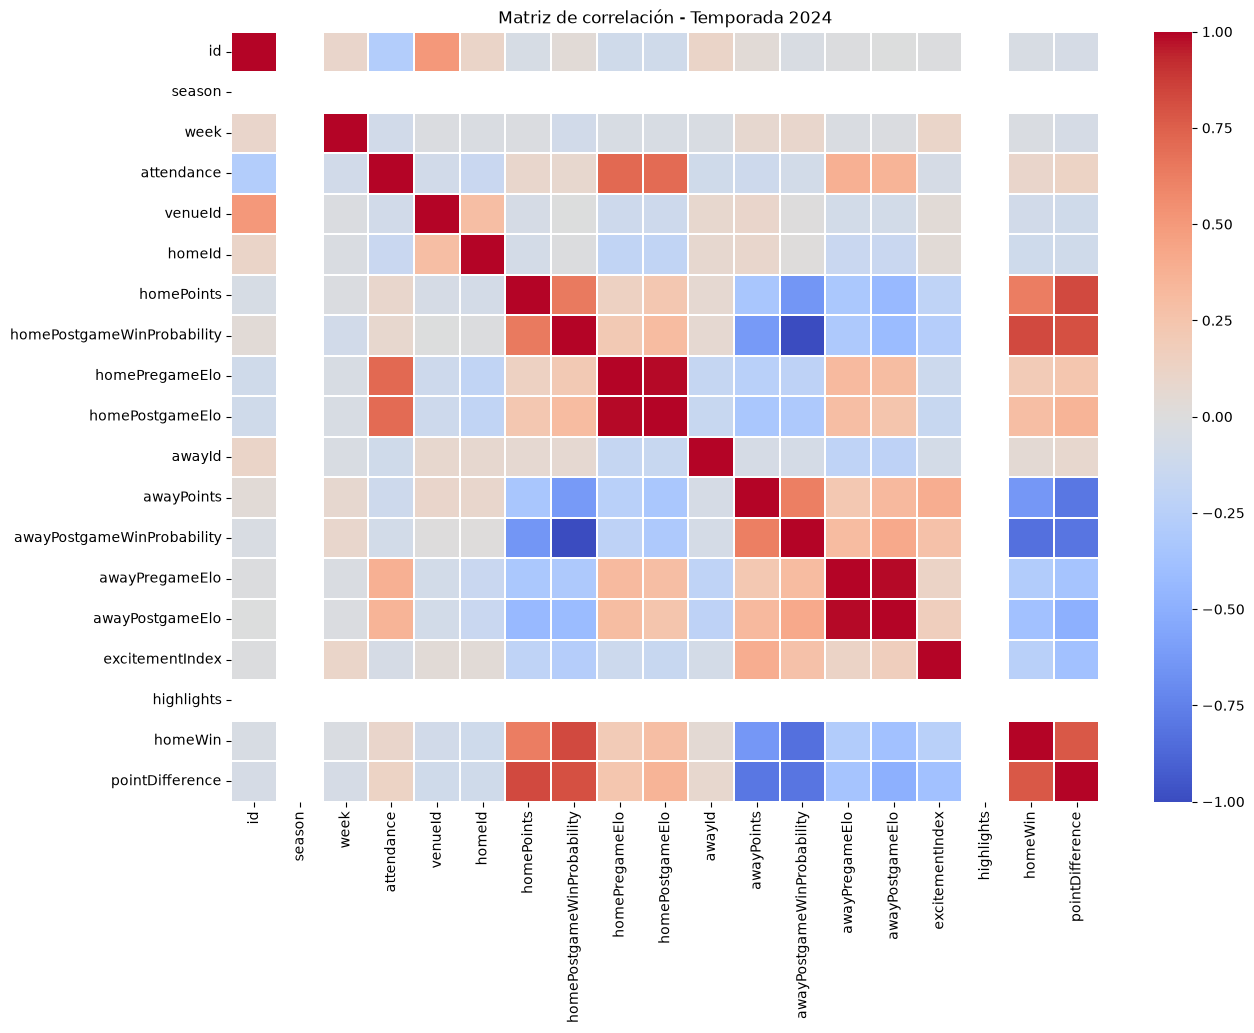

In [25]:
# Seleccionar variables numéricas
numeric_df = df_eda.select_dtypes(include="number")

# Matriz de correlación
correlation_matrix = numeric_df.corr()

# Visualización
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    annot=False,
    linewidths=0.3
)

plt.title("Matriz de correlación - Temporada 2024")
plt.show()

estamos observando?
Esta es una matriz de correlacion.

Nos permite identificar que variables tienen relaciones entre si.

La escala de colores representa:

- Rojo: correlación positiva.
- Azul: correlación negativa.
- Gris o blanco: correlación cercana a cero.
Los valores de correlación van desde -1 hasta +1.

Hallazgos importantes

Hay cuatro observaciones que debemos registrar.

A. homePoints y homeWin

Existe una relación positiva: cuando el equipo local anota más puntos, aumenta la posibilidad de que gane.

B. awayPoints y homeWin

Existe una relación negativa: cuando el visitante anota más puntos, disminuye la posibilidad de victoria local.

C. homePregameElo y awayPregameElo

Observamos una relación entre las métricas Elo de ambos equipos. Estas variables representan la valoración de fuerza de los equipos antes del encuentro.

D. pointDifference y homeWin

Existe una relación positiva muy fuerte. Esto es lógico porque pointDifference se calcula utilizando los puntos finales y homeWin representa el resultado del partido.

3. ¡Atención! Aquí encontramos un posible Data Leakage
Esta es una de las partes más importantes de nuestro proyecto.

Si nuestro objetivo es predecir quién ganará un partido antes de que comience, no podemos utilizar información que solamente conocemos después del partido.

- Identificar y documentar las variables que pueden provocar Data Leakage.



- Escribir las conclusiones finales del análisis exploratorio.

# Conclusiones del Análisis Exploratorio de Datos (EDA)

## 1. Descripción general
Se analizaron 3,799 registros correspondientes a la temporada 2024 de fútbol americano.

## 2. Distribución de puntos
- Promedio de puntos locales: 28.66.
- Promedio de puntos visitantes: 23.95.
- Los equipos locales presentan un promedio de anotación superior.

## 3. Ventaja de jugar en casa
- Victorias locales: 57.44%.
- Victorias visitantes: 42.22%.
- Empates: 0.34%.

Los resultados sugieren una ventaja de los equipos locales.

## 4. Calidad de los datos
- Registros duplicados: 0.
- IDs duplicados: 0.
- Se identificaron columnas con diferentes porcentajes de valores faltantes.

## 5. Correlaciones
Se identificaron relaciones entre las puntuaciones, las métricas Elo y los resultados de los partidos.

## 6. Riesgo de Data Leakage
Se identificaron variables posteriores al partido que no deben utilizarse para realizar predicciones previas al encuentro.

## 7. Conclusión general
El análisis exploratorio permitió comprender la estructura del dataset, identificar patrones de puntuación, estudiar la ventaja de jugar en casa y detectar posibles problemas de calidad de datos.

El siguiente paso será realizar Feature Engineering para preparar las variables que utilizará nuestro modelo de Machine Learning.